# Lab 4: Predict who wins Nim (supervised learning), by hand and with scikit-learn
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**. scikit-learn is part of `environment.yml`.

**Task:** for a Nim position (3 piles, 0 to 7 stones each) predict whether the player to move **loses**. Only 12.5 percent of the positions are losing, so accuracy alone is misleading.

**Part 1 (cells 1 to 4):** everything by hand with NumPy. **Part 2 (cells 5 to 8):** the same project with scikit-learn.

## Cell 1: Data and labels (512 positions)

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

memo = {}                                    # remember answers so we never compute a position twice

def wins(piles):
    """True if the player to move wins Nim from this position (both play perfectly)."""
    if piles in memo:
        return memo[piles]
    result = False
    for i, n in enumerate(piles):
        for take in range(1, n + 1):
            nxt = piles[:i] + (n - take,) + piles[i + 1:]
            if not wins(nxt):                # a move that leaves the opponent in a losing position
                result = True
    memo[piles] = result
    return result

rows = []
for a in range(8):
    for b in range(8):
        for c in range(8):
            rows.append({"p1": a, "p2": b, "p3": c, "loses": not wins((a, b, c))})

df = pd.DataFrame(rows)                      # one row = one position; label "loses" = the player to move loses
print(df.shape)
print(df["loses"].value_counts())
print(df.head())

(512, 4)
loses
False    448
True      64
Name: count, dtype: int64
   p1  p2  p3  loses
0   0   0   0   True
1   0   0   1  False
2   0   0   2  False
3   0   0   3  False
4   0   0   4  False


## Cell 2: Train/test split and the baseline (by hand)

In [18]:
rng = np.random.default_rng(0)
order = rng.permutation(len(df))             # shuffled row numbers
n_train = int(0.7 * len(df))                 # 70% train, 30% test
train = df.iloc[order[:n_train]]
test = df.iloc[order[n_train:]]

X_train = train[["p1", "p2", "p3"]].to_numpy()
y_train = train["loses"].to_numpy()
X_test = test[["p1", "p2", "p3"]].to_numpy()
y_test = test["loses"].to_numpy()

baseline = np.zeros(len(y_test), dtype=bool)     # baseline: always say "the player wins" (loses = False)
print("train rows:", len(train), "  test rows:", len(test))
print("baseline accuracy:", round((baseline == y_test).mean(), 3))

train rows: 358   test rows: 154
baseline accuracy: 0.883


## Cell 3: k-NN from scratch

In [19]:
def knn_predict(x, k=3):
    distances = np.abs(X_train - x).sum(axis=1)          # Manhattan distance to every training row
    nearest = np.argsort(distances, kind="stable")[:k]   # the k closest rows
    return y_train[nearest].mean() > 0.5                 # majority vote

pred = np.array([knn_predict(x) for x in X_test])
print("k-NN (from scratch) accuracy:", round((pred == y_test).mean(), 3))

k-NN (from scratch) accuracy: 0.792


## Cell 4: Metrics by hand

In [20]:
tp = ((pred == True) & (y_test == True)).sum()      # predicted "loses" and it really loses
fp = ((pred == True) & (y_test == False)).sum()     # predicted "loses" but it wins
fn = ((pred == False) & (y_test == True)).sum()     # missed a losing position
tn = ((pred == False) & (y_test == False)).sum()    # predicted "wins" and it wins

accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"accuracy={accuracy:.3f}  precision={precision:.3f}  recall={recall:.3f}")

TP=0  FP=14  FN=18  TN=122
accuracy=0.792  precision=0.000  recall=0.000


In [21]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Part 2: the same project with scikit-learn

## Cell 5: Four models, same metrics

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

X = df[["p1", "p2", "p3"]]
y = df["loses"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

models = {
    "baseline (always wins)": DummyClassifier(strategy="most_frequent"),
    "k-NN (k=3)": KNeighborsClassifier(n_neighbors=3, metric="manhattan"),
    "decision tree": DecisionTreeClassifier(random_state=0),
    "logistic regression": LogisticRegression(max_iter=1000),
}
results = []
for name, model in models.items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    results.append({"model": name,
                    "accuracy": accuracy_score(y_te, pred),
                    "precision": precision_score(y_te, pred, zero_division=0),
                    "recall": recall_score(y_te, pred, zero_division=0)})

table1 = pd.DataFrame(results).round(3)
print(table1)

                    model  accuracy  precision  recall
0  baseline (always wins)     0.877        0.0     0.0
1              k-NN (k=3)     0.773        0.0     0.0
2           decision tree     0.734        0.0     0.0
3     logistic regression     0.877        0.0     0.0


## Cell 6: Feature engineering with nim_sum

In [23]:
df["nim_sum"] = df["p1"] ^ df["p2"] ^ df["p3"]       # a new feature made from the old ones
X2 = df[["p1", "p2", "p3", "nim_sum"]]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.3, random_state=0, stratify=y)

results2 = []
for name, model in models.items():
    model.fit(X2_tr, y2_tr)
    pred = model.predict(X2_te)
    results2.append({"model": name,
                     "accuracy": accuracy_score(y2_te, pred),
                     "precision": precision_score(y2_te, pred, zero_division=0),
                     "recall": recall_score(y2_te, pred, zero_division=0)})

table2 = pd.DataFrame(results2).round(3)
print(table2)

                    model  accuracy  precision  recall
0  baseline (always wins)     0.877      0.000   0.000
1              k-NN (k=3)     0.942      0.708   0.895
2           decision tree     1.000      1.000   1.000
3     logistic regression     1.000      1.000   1.000


## Cell 7: Overfitting curve (k-NN)

    k  train_acc  test_acc
0   1      1.000     0.760
1   3      0.816     0.773
2   5      0.855     0.838
3   7      0.874     0.877
4   9      0.872     0.877
5  11      0.874     0.864
6  15      0.872     0.870


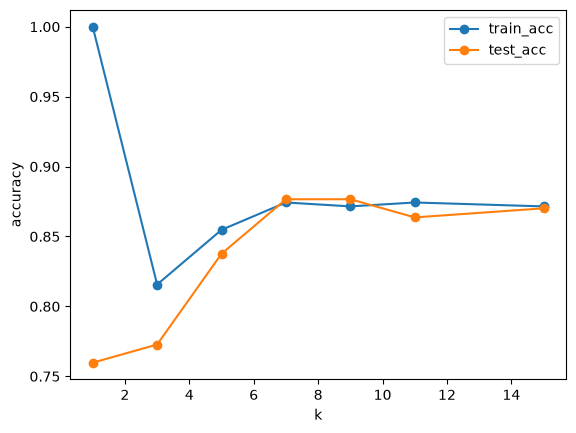

In [24]:
curve = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="manhattan").fit(X_tr, y_tr)
    curve.append({"k": k, "train_acc": knn.score(X_tr, y_tr), "test_acc": knn.score(X_te, y_te)})

curve = pd.DataFrame(curve)
print(curve.round(3))
curve.plot(x="k", y=["train_acc", "test_acc"], marker="o")
plt.ylabel("accuracy")
plt.show()

## Cell 8: Confusion matrix

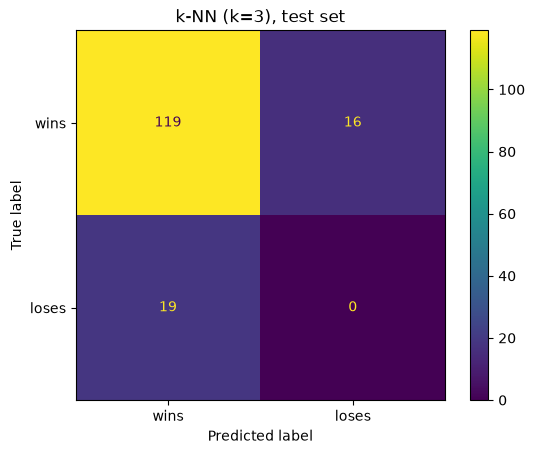

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

knn = KNeighborsClassifier(n_neighbors=3, metric="manhattan").fit(X_tr, y_tr)
ConfusionMatrixDisplay.from_estimator(knn, X_te, y_te, display_labels=["wins", "loses"])
plt.title("k-NN (k=3), test set")
plt.show()

## Interpretation (write it in README)
Observation, reason, conclusion. Example: *k-NN with raw piles has recall 0 (observation); raw piles do not show the XOR pattern (reason); we need a better feature such as nim_sum (conclusion).*

## Challenges
Tree max_depth curve, bigger piles, other features (sum, max), F1 score.

In [26]:
# -------------------------------------------------------------
# Challenge 1: Evaluation with F1-Score on all models
# -------------------------------------------------------------
from sklearn.metrics import f1_score

results_challenge = []
for name, model in models.items():
    model.fit(X2_tr, y2_tr)
    pred = model.predict(X2_te)
    results_challenge.append({
        "model": name,
        "accuracy": accuracy_score(y2_te, pred),
        "precision": precision_score(y2_te, pred, zero_division=0),
        "recall": recall_score(y2_te, pred, zero_division=0),
        "f1_score": f1_score(y2_te, pred, zero_division=0)
    })

table_challenge = pd.DataFrame(results_challenge).round(3)
print("--- Table with F1-Score (with nim_sum) ---")
print(table_challenge)

--- Table with F1-Score (with nim_sum) ---
                    model  accuracy  precision  recall  f1_score
0  baseline (always wins)     0.877      0.000   0.000     0.000
1              k-NN (k=3)     0.942      0.708   0.895     0.791
2           decision tree     1.000      1.000   1.000     1.000
3     logistic regression     1.000      1.000   1.000     1.000


--- Decision Tree Depth Tuning (Raw Features) ---
   max_depth  train_acc  test_acc  test_recall
0          1      0.874     0.877          0.0
1          2      0.874     0.877          0.0
2          3      0.874     0.877          0.0
3          4      0.877     0.870          0.0
4          5      0.877     0.870          0.0
5          6      0.877     0.870          0.0
6          7      0.885     0.844          0.0
7          8      0.905     0.818          0.0
8          9      0.922     0.773          0.0
9         10      0.947     0.740          0.0


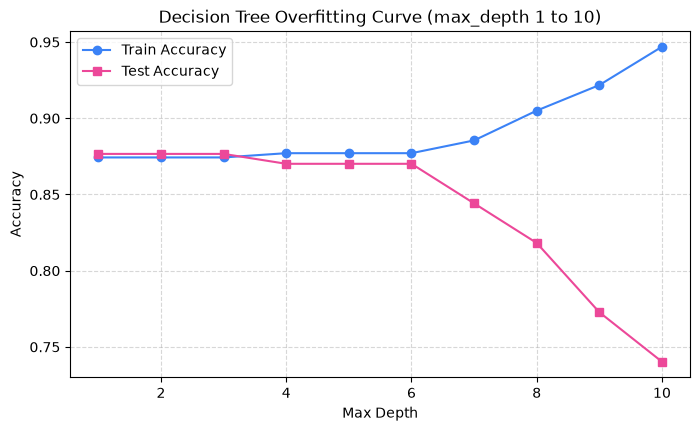

In [27]:
# -------------------------------------------------------------
# Challenge 2: Decision Tree max_depth curve (Overfitting analysis)
# -------------------------------------------------------------
depth_curve = []
# بررسی عمق درخت بدون ویژگی nim_sum روی داده‌های خام
for d in range(1, 11):
    dt = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr)
    depth_curve.append({
        "max_depth": d,
        "train_acc": dt.score(X_tr, y_tr),
        "test_acc": dt.score(X_te, y_te),
        "test_recall": recall_score(y_te, dt.predict(X_te), zero_division=0)
    })

depth_df = pd.DataFrame(depth_curve)
print("--- Decision Tree Depth Tuning (Raw Features) ---")
print(depth_df.round(3))

plt.figure(figsize=(8, 4.5))
plt.plot(depth_df["max_depth"], depth_df["train_acc"], marker="o", label="Train Accuracy", color="#3b82f6")
plt.plot(depth_df["max_depth"], depth_df["test_acc"], marker="s", label="Test Accuracy", color="#ec4899")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Overfitting Curve (max_depth 1 to 10)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("tree_depth_curve.png", dpi=300, bbox_inches="tight")
plt.show()